# 08 · Hybrid Ensemble (GBM + Prophet + LSTM)

Blend three very different forecasters. Weights are proportional to 1/MAE on the holdout so better models get more influence.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


In [2]:
series = daily.set_index("date")["units"].astype(float)
train, test = series.iloc[:-HOLDOUT_DAYS], series.iloc[-HOLDOUT_DAYS:]

## 1. Backtest all models and build the ensemble

In [3]:
from src.forecasting.ensemble import available_models, run_forecasting
models = available_models()
print("models:", list(models))
res = run_forecasting(series, models)
res["metrics"].round(3)

models: ['gbm', 'prophet', 'lstm']


,mae,rmse,wape,bias
gbm,15.649,19.848,0.122,4.213
prophet,14.030,18.108,0.110,3.080
lstm,17.623,23.873,0.138,-12.855
ensemble (hybrid),13.099,17.140,0.102,-1.255


ensemble weights:
gbm        0.3330
prophet    0.3714
lstm       0.2957
Name: mae, dtype: float64


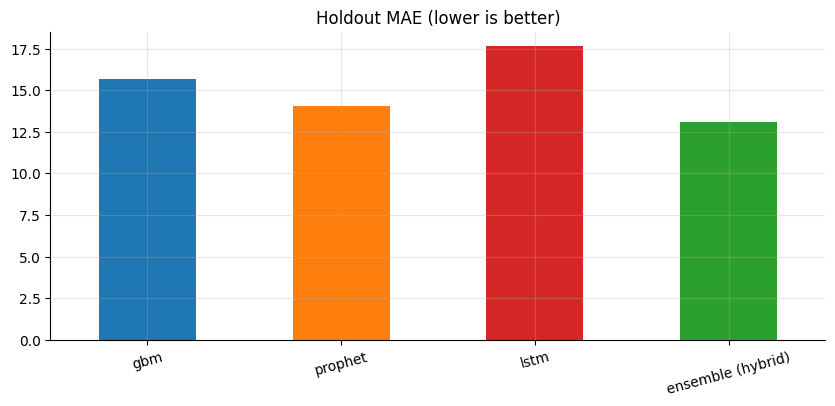

In [4]:
print("ensemble weights:"); print(res["weights"])
res["metrics"]["mae"].plot.bar(color=["C0","C1","C3","C2"], title="Holdout MAE (lower is better)", rot=15); plt.show()

## 2. Backtest plot

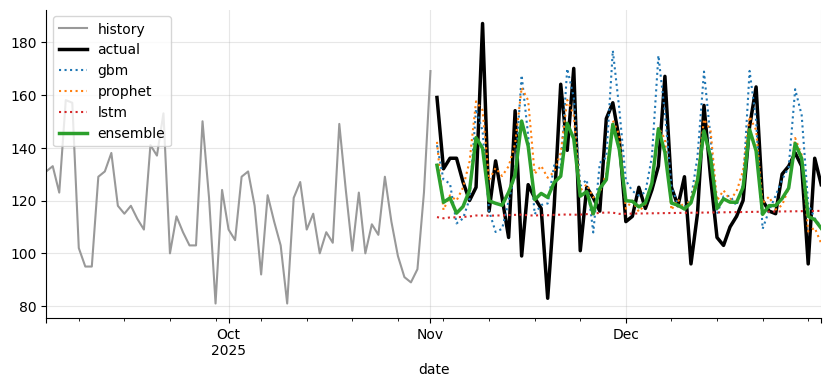

In [5]:
bt = res["backtest"].set_index("date")
ax = series.iloc[-120:-HOLDOUT_DAYS].plot(color="#999", label="history")
bt["actual"].plot(ax=ax, color="k", lw=2.5)
for c, col in zip([c for c in bt.columns if c not in ("actual", "ensemble")], ["C0", "C1", "C3"]):
    bt[c].plot(ax=ax, ls=":", color=col)
bt["ensemble"].plot(ax=ax, color="C2", lw=2.5); plt.legend(); plt.show()

## 3. Is inverse-error weighting better than a simple average?

In [6]:
from src.forecasting.ensemble import regression_metrics
names = [c for c in bt.columns if c not in ("actual", "ensemble")]
equal = bt[names].mean(axis=1)
pd.DataFrame({"equal weights": regression_metrics(bt.actual, equal),
              "inverse-MAE weights": regression_metrics(bt.actual, bt.ensemble)}).T.round(3)

,mae,rmse,wape,bias
equal weights,13.077,17.197,0.102,-1.854
inverse-MAE weights,13.099,17.140,0.102,-1.255


## 4. Why the blend wins: errors are partly independent

In [7]:
errs = bt[names].sub(bt["actual"], axis=0)
print("Correlation of model errors:"); errs.corr().round(2)

Correlation of model errors:


,gbm,prophet,lstm
gbm,1.00,0.83,0.55
prophet,0.83,1.00,0.73
lstm,0.55,0.73,1.00


## 5. 30-day forward forecast

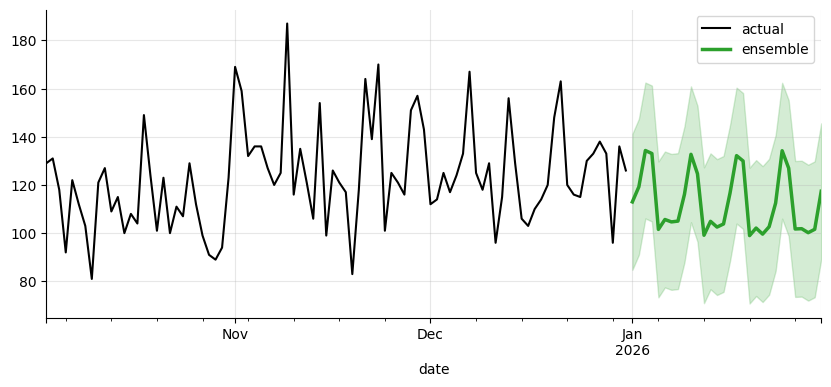

Next 30 days: 3,379 units


In [8]:
f = res["future"].set_index("date")
ax = series.tail(90).plot(color="k", label="actual"); f["ensemble"].plot(ax=ax, color="C2", lw=2.5, label="ensemble")
ax.fill_between(f.index, f["ensemble_lower"], f["ensemble_upper"], alpha=.2, color="C2"); plt.legend(); plt.show()
print(f"Next {len(f)} days: {f['ensemble'].sum():,.0f} units")